
# SVM 全特征基线实验

## 一、实验目的

使用 UCI HAR 数据集提供的全部 561 个工程特征训练支持向量机（SVM），建立人体活动识别的基线模型。

## 二、实验数据

- 训练集：7,352 个样本。
- 测试集：2,947 个样本。
- 特征数量：561。
- 活动类别：6 类。
- 数据划分：保留数据集官方提供的训练集和测试集。

## 三、实验方法

1. 读取官方训练集和测试集。
2. 使用训练集拟合数据标准化器。
3. 使用标准化后的训练数据训练 SVM。
4. 在官方测试集上评估模型。
5. 记录准确率、宏平均 F1、各类别召回率、混淆矩阵和运行时间。

## 四、实验注意事项

- 本实验不进行特征筛选，保留全部 561 个特征。
- 标准化参数只从训练集学习。
- 不使用官方测试集进行特征选择或模型调参。
- 所有评价指标均以实际运行结果为准。


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

# 确定项目根目录和数据集目录
项目根目录 = Path.cwd().parent
数据目录 = 项目根目录 / "data" / "raw" / "UCI HAR Dataset"

# 读取官方训练集
X_train = pd.read_csv(
    数据目录 / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    数据目录 / "train" / "y_train.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

# 读取官方测试集
X_test = pd.read_csv(
    数据目录 / "test" / "X_test.txt",
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    数据目录 / "test" / "y_test.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

# 检查数据维度
print("训练集特征维度：", X_train.shape)
print("测试集特征维度：", X_test.shape)
print("训练集标签数量：", len(y_train))
print("测试集标签数量：", len(y_test))

# 检查特征数量与标签范围
assert X_train.shape == (7352, 561), "训练集维度不符合预期"
assert X_test.shape == (2947, 561), "测试集维度不符合预期"
assert len(y_train) == len(X_train), "训练集特征与标签数量不一致"
assert len(y_test) == len(X_test), "测试集特征与标签数量不一致"
assert set(y_train.unique()) == {1, 2, 3, 4, 5, 6}
assert set(y_test.unique()) == {1, 2, 3, 4, 5, 6}

print("数据检查通过，可以开始训练 SVM。")


训练集特征维度： (7352, 561)
测试集特征维度： (2947, 561)
训练集标签数量： 7352
测试集标签数量： 2947
数据检查通过，可以开始训练 SVM。


In [2]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 第二步：读取六类活动的名称
数据目录 = 项目根目录 / "data" / "raw" / "UCI HAR Dataset"

activity_info = pd.read_csv(
    数据目录 / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

活动名称 = (
    activity_info
    .sort_values("activity_id")["activity_name"]
    .tolist()
)

print("活动类别：", 活动名称)

# 第三步：建立标准化 + SVM 的流水线
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

# 第四步：训练模型并记录训练时间
训练开始时间 = time.perf_counter()

svm_model.fit(X_train, y_train)

训练耗时 = time.perf_counter() - 训练开始时间

# 第五步：使用官方测试集进行预测
预测开始时间 = time.perf_counter()

y_pred = svm_model.predict(X_test)

预测耗时 = time.perf_counter() - 预测开始时间

# 第六步：计算评价指标
准确率 = accuracy_score(y_test, y_pred)

宏平均精确率 = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

宏平均召回率 = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

宏平均F1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("\n========== SVM 全特征基线结果 ==========")
print(f"特征数量：{X_train.shape[1]}")
print(f"训练样本数：{len(X_train)}")
print(f"测试样本数：{len(X_test)}")
print(f"准确率 Accuracy：{准确率:.4f}")
print(f"宏平均精确率 Macro-Precision：{宏平均精确率:.4f}")
print(f"宏平均召回率 Macro-Recall：{宏平均召回率:.4f}")
print(f"宏平均 F1 Macro-F1：{宏平均F1:.4f}")
print(f"模型训练时间：{训练耗时:.3f} 秒")
print(f"测试集预测总时间：{预测耗时:.3f} 秒")
print(
    f"平均每个样本预测时间："
    f"{预测耗时 / len(X_test) * 1000:.4f} 毫秒"
)

# 第七步：查看各类活动的分类表现
print("\n========== 各类别分类报告 ==========")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 2, 3, 4, 5, 6],
        target_names=活动名称,
        digits=4,
        zero_division=0
    )
)

# 第八步：输出混淆矩阵
混淆矩阵 = confusion_matrix(
    y_test,
    y_pred,
    labels=[1, 2, 3, 4, 5, 6]
)

print("========== 混淆矩阵 ==========")
print(混淆矩阵)


活动类别： ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']

========== SVM 全特征基线结果 ==========
特征数量：561
训练样本数：7352
测试样本数：2947
准确率 Accuracy：0.9522
宏平均精确率 Macro-Precision：0.9528
宏平均召回率 Macro-Recall：0.9508
宏平均 F1 Macro-F1：0.9515
模型训练时间：1.626 秒
测试集预测总时间：1.675 秒
平均每个样本预测时间：0.5685 毫秒

========== 各类别分类报告 ==========
                    precision    recall  f1-score   support

           WALKING     0.9602    0.9718    0.9659       496
  WALKING_UPSTAIRS     0.9287    0.9682    0.9480       471
WALKING_DOWNSTAIRS     0.9772    0.9190    0.9472       420
           SITTING     0.9384    0.9002    0.9189       491
          STANDING     0.9162    0.9455    0.9306       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9522      2947
         macro avg     0.9528    0.9508    0.9515      2947
      weighted avg     0.9526    0.9522    0.9521      2947

========== 混淆矩阵 ==========
[[482   6   8   0   0   0]


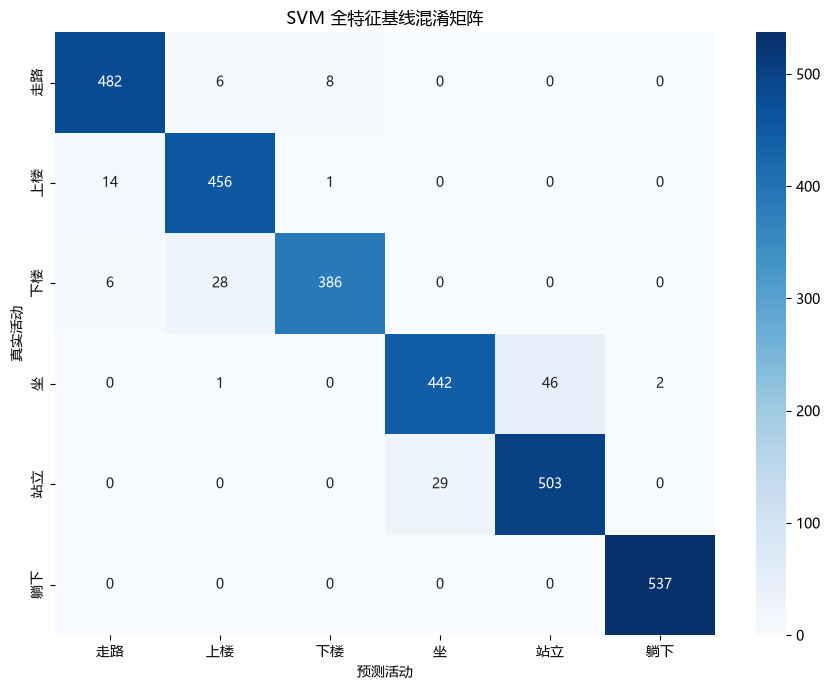

混淆矩阵图片已保存到： d:\smartphone-feature-selection\results\figures\confusion_matrix.png


In [3]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 中文活动名称，顺序对应标签 1—6
活动中文名称 = [
    "走路",
    "上楼",
    "下楼",
    "坐",
    "站立",
    "躺下"
]

# 设置中文字体
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Arial"
]
plt.rcParams["axes.unicode_minus"] = False

# 绘制混淆矩阵
plt.figure(figsize=(9, 7))

sns.heatmap(
    混淆矩阵,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=活动中文名称,
    yticklabels=活动中文名称
)

plt.title("SVM 全特征基线混淆矩阵")
plt.xlabel("预测活动")
plt.ylabel("真实活动")
plt.tight_layout()

# 保存图片
项目根目录 = Path.cwd().parent
图表目录 = 项目根目录 / "results" / "figures"
图表目录.mkdir(parents=True, exist_ok=True)

混淆矩阵路径 = 图表目录 / "confusion_matrix.png"
plt.savefig(
    混淆矩阵路径,
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("混淆矩阵图片已保存到：", 混淆矩阵路径)


In [4]:

# 整理 SVM 全特征基线的总体结果
SVM总体结果 = pd.DataFrame([{
    "模型": "SVM",
    "特征选择方法": "无（完整特征）",
    "特征数量": X_train.shape[1],
    "训练样本数": len(X_train),
    "测试样本数": len(X_test),
    "准确率": 准确率,
    "宏平均精确率": 宏平均精确率,
    "宏平均召回率": 宏平均召回率,
    "宏平均F1": 宏平均F1,
    "训练时间_秒": 训练耗时,
    "测试预测总时间_秒": 预测耗时,
    "平均单样本预测时间_毫秒": 预测耗时 / len(X_test) * 1000
}])

结果目录 = 项目根目录 / "results"
结果目录.mkdir(parents=True, exist_ok=True)

总体结果路径 = 结果目录 / "svm_baseline_metrics.csv"
SVM总体结果.to_csv(
    总体结果路径,
    index=False,
    encoding="utf-8-sig"
)

print("总体指标已保存到：", 总体结果路径)
display(SVM总体结果)


总体指标已保存到： d:\smartphone-feature-selection\results\svm_baseline_metrics.csv


,模型,特征选择方法,特征数量,训练样本数,测试样本数,准确率,宏平均精确率,宏平均召回率,宏平均F1,训练时间_秒,测试预测总时间_秒,平均单样本预测时间_毫秒
0,SVM,无（完整特征）,561,7352,2947,0.952155,0.952837,0.950778,0.951479,1.625886,1.675332,0.568487


In [5]:

# 保存各类别的精确率、召回率和 F1
分类报告字典 = classification_report(
    y_test,
    y_pred,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=活动中文名称,
    output_dict=True,
    zero_division=0
)

分类报告表 = pd.DataFrame(分类报告字典).transpose()

分类报告路径 = 结果目录 / "svm_classification_report.csv"
分类报告表.to_csv(
    分类报告路径,
    index=True,
    encoding="utf-8-sig"
)

print("分类报告已保存到：", 分类报告路径)
display(分类报告表)


分类报告已保存到： d:\smartphone-feature-selection\results\svm_classification_report.csv


,precision,recall,f1-score,support
走路,0.960159,0.971774,0.965932,496.000000
上楼,0.928717,0.968153,0.948025,471.000000
下楼,0.977215,0.919048,0.947239,420.000000
坐,0.938429,0.900204,0.918919,491.000000
站立,0.916211,0.945489,0.930620,532.000000
躺下,0.996289,1.000000,0.998141,537.000000
accuracy,0.952155,0.952155,0.952155,0.952155
macro avg,0.952837,0.950778,0.951479,2947.000000
weighted avg,0.952594,0.952155,0.952068,2947.000000



## SVM 全特征基线实验结果

### 1. 实验设置

- 模型：支持向量机（SVM）。
- 核函数：RBF（径向基函数）。
- 参数：C = 1.0，gamma = scale。
- 输入特征数：561。
- 训练样本数：7,352。
- 测试样本数：2,947。
- 数据划分：使用官方训练集和测试集。
- 标准化：仅使用训练集拟合标准化器。

### 2. 总体评价结果

| 指标 | 实验结果 |
|---|---:|
| 准确率 Accuracy | 95.22% |
| 宏平均精确率 Macro-Precision | 95.28% |
| 宏平均召回率 Macro-Recall | 95.08% |
| 宏平均 F1 Macro-F1 | 95.15% |
| 模型训练时间 | 1.626 秒 |
| 测试集预测总时间 | 1.675 秒 |
| 平均每个测试样本预测时间 | 0.5685 毫秒 |

### 3. 各类活动的识别表现

| 活动 | 精确率 | 召回率 | F1 |
|---|---:|---:|---:|
| 走路 | 96.02% | 97.18% | 96.59% |
| 上楼 | 92.87% | 96.82% | 94.80% |
| 下楼 | 97.72% | 91.90% | 94.72% |
| 坐 | 93.84% | 90.02% | 91.89% |
| 站立 | 91.62% | 94.55% | 93.06% |
| 躺下 | 99.63% | 100.00% | 99.81% |

### 4. 主要观察

1. 模型总体分类表现较好，准确率为 95.22%，宏平均 F1 为 95.15%。
2. 躺下活动的召回率为 100%，本次测试集中 537 个躺下样本均被正确识别。
3. 下楼活动的召回率为 91.90%，存在与上楼活动混淆的情况。
4. 坐和站立之间存在双向混淆：46 个坐样本被预测为站立，29 个站立样本被预测为坐。

### 5. 混淆矩阵

图表路径：

`results/figures/confusion_matrix_svm_baseline.png`

### 6. 本阶段结论

在全部 561 个特征下，SVM 建立了可供后续特征选择实验比较的基线。

下一步将开展互信息（MI）特征选择，比较不同特征数量下的分类性能与计算开销。

本次结果属于当前固定参数设置下的实验结果，不代表 SVM 已完成超参数优化。
